# Decision Trees, Bagging & Random Forest
### Will a final-year student get placed? - from one tree to a whole forest

**Dataset (provided separately):** `student_placement.csv` - 7000 students:
- Features: `cgpa`, `backlogs`, `internships`, `projects`, `coding_hours_per_week`, `communication_score`, `certifications`, `hostel_resident`, `home_distance_km`
- `placed` (0/1) - the **classification** target
- `package_lpa` - the salary package in lakhs per annum, the **regression** target. It exists only for placed students (an unplaced student has no package, so it is blank).

Two columns, `hostel_resident` and `home_distance_km`, are **deliberately irrelevant** - they should have no real effect on placement. Later we will see which importance method exposes them - and which one gets fooled.

**Roadmap (theory in markdown, then code below it):**
1. Decision trees - splitting, entropy, information gain, Gini, leaves, pruning, hyperparameters, visualization (classifier and regressor)
2. Ensembles and **bagging** - why many models beat one
3. **Random Forest** - bagging plus random features; bias-variance revisited; feature importance; out-of-bag (OOB) score; hyperparameters; forest vs single tree

Two code cells hide a small deliberate bug marked `# FIX ME`, each with a hint. Find and fix both - the results look suspicious until you do.

In [7]:
import os
data_paths = {}
for base in ['/kaggle/input', '.']:            # Kaggle first, then the current folder (for running locally)
    if os.path.exists(base):
        for dirname, _, filenames in os.walk(base):
            for filename in filenames:
                if 'student_placement' in filename and filename.endswith('.csv'):
                    data_paths['placement'] = os.path.join(dirname, filename)
print(data_paths)
# If this prints an empty dict: click 'Add Input' and attach student_placement.csv first

{'placement': '/kaggle/input/datasets/manikantaarigela1/student-placement/student_placement.csv'}


In [8]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, BaggingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

sns.set_style('whitegrid')

---
# Part 1 - Load, understand and split the data

## Theory
Same routine as always: look at the data, check for missing values, then split into a **training set** (the model learns from it) and a **test set** (hidden, used only for an honest final check).

**Two things to notice today**
- **No scaling needed.** Trees (and forests) only ask yes/no questions like "is cgpa <= 7.5?" about ONE feature at a time, so the size of the numbers does not matter. (Yesterday's KNN needed scaling because it measured distances.)
- **Missing `package_lpa` is not a data error.** It is blank because those students were not placed. For the regression part we will simply use only the placed students.
- **Data leakage warning:** `package_lpa` is only known AFTER a student is placed. Using it as a feature to predict `placed` would be cheating - the model would just learn "has a package = placed". We keep it out of the features.

In [9]:
assert 'placement' in data_paths, "Attach student_placement.csv via Add Input first."
df = pd.read_csv(data_paths['placement'])
print(df.shape)
df.head()

(7000, 11)


,cgpa,backlogs,internships,projects,coding_hours_per_week,communication_score,certifications,hostel_resident,home_distance_km,placed,package_lpa
0,7.30,0,1,4,20.3,7.0,2,0,191.0,1,8.69
1,7.60,1,0,3,7.0,3.3,0,0,200.0,1,6.61
2,7.03,0,1,2,5.5,3.8,2,0,63.0,1,6.16
3,6.41,0,1,2,10.1,4.3,0,0,219.0,0,NaN
4,6.85,0,2,1,14.0,6.3,2,1,48.0,1,8.10


In [10]:
print(df.isnull().sum())
print()
print('Placement rate:', round(df['placed'].mean(), 3))
df.describe().round(2)

cgpa                        0
backlogs                    0
internships                 0
projects                    0
coding_hours_per_week       0
communication_score         0
certifications              0
hostel_resident             0
home_distance_km            0
placed                      0
package_lpa              2748
dtype: int64

Placement rate: 0.607


,cgpa,backlogs,internships,projects,coding_hours_per_week,communication_score,certifications,hostel_resident,home_distance_km,placed,package_lpa
count,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00,7000.0,7000.00,7000.00,4252.00
mean,7.28,0.71,0.90,2.51,8.83,6.00,1.51,0.5,199.97,0.61,7.23
std,0.99,0.83,0.94,1.57,5.88,1.79,1.24,0.5,113.70,0.49,1.68
min,4.50,0.00,0.00,0.00,0.00,1.00,0.00,0.0,1.00,0.00,2.34
25%,6.61,0.00,0.00,1.00,4.60,4.80,1.00,0.0,102.00,0.00,6.06
50%,7.28,1.00,1.00,2.00,7.50,6.00,1.00,0.0,201.00,1.00,7.06
75%,7.95,1.00,1.00,3.00,11.70,7.20,2.00,1.0,298.00,1.00,8.16
max,10.00,6.00,4.00,9.00,35.00,10.00,7.00,1.0,400.00,1.00,13.99


In [11]:
feature_cols = ['cgpa', 'backlogs', 'internships', 'projects', 'coding_hours_per_week',
                'communication_score', 'certifications', 'hostel_resident', 'home_distance_km']
X = df[feature_cols].values
y = df['placed'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape[0], '| Test:', X_test.shape[0])

Train: 5600 | Test: 1400


## A quick reminder of the metrics (from earlier classes)
Positive = "student gets placed".
- **TP** - predicted placed, and was placed. **TN** - predicted not placed, and was not placed.
- **FP** - predicted placed, but was NOT placed (false hope). **FN** - predicted not placed, but WAS placed (a student wrongly discouraged).
- *Trick: the 2nd word is what the model said; the 1st word says whether it was right.*

Accuracy = (TP+TN)/all, Precision = TP/(TP+FP), Recall = TP/(TP+FN), Specificity = TN/(TN+FP), F1 = balance of precision and recall, AUC = how well the model ranks placed students above unplaced ones across every threshold.

In [12]:
def evaluate(name, y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    r = {'model': name,
         'accuracy': (tp + tn) / (tp + tn + fp + fn),
         'precision': tp / (tp + fp) if (tp + fp) else 0.0,
         'recall': tp / (tp + fn) if (tp + fn) else 0.0,
         'specificity': tn / (tn + fp) if (tn + fp) else 0.0}
    p, rec = r['precision'], r['recall']
    r['f1'] = 2 * p * rec / (p + rec) if (p + rec) else 0.0
    if y_prob is not None:
        r['auc'] = roc_auc_score(y_true, y_prob)
    return r

def show_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['not placed', 'placed']).plot(cmap='Blues')
    plt.title(title)
    plt.show()

---
# Part 2 - Decision Trees

## 2.1 The idea
A decision tree is a flowchart of yes/no questions. To predict, start at the top, answer each question about the student, follow the branches, and read the answer at the end.

**Analogy - a recruiter's shortlisting flowchart:** "CGPA above 7.5? If yes, any backlogs? If no, any internship?..." Each question narrows the pool until the recruiter reaches a decision. (Or think of the game of 20 Questions: a good player asks the question that cuts the possibilities down the most.)

```
                    [ cgpa <= 7.5 ? ]                  <-- ROOT node (first question)
                     /            \
                  Yes              No
                  /                  \
       [ backlogs >= 1 ? ]     [ internships >= 1 ? ]   <-- INTERNAL nodes (more questions)
          /        \               /          \
   NOT PLACED    PLACED        PLACED       PLACED      <-- LEAF nodes (final answers)
```

- **Root node** - the first question. **Internal node** - any later question. **Branch** - a Yes/No answer.
- **Leaf node** - the end of a path, holding the prediction: the **majority class** in that leaf (classification) or the **average value** of the samples in it (regression).
- **Depth** - how many questions deep the longest path goes.

## 2.2 How does the tree pick its questions? Splitting and impurity
At every node the tree tries many candidate splits (`cgpa <= 7.5`, `projects <= 3`, ...) and keeps the one that makes the resulting groups as **pure** as possible. A group is **pure** when it holds only one class.

**Analogy - a bag of marbles:** a bag with only red marbles is pure (no surprise when you pull one out). A bag that is half red, half blue is as mixed as it can be. A good question sorts the marbles into bags that are each closer to one colour.

We need a number for "how mixed is this group". With `p` the share of each class:

```
Gini index = 1 - (p1^2 + p2^2 + ...)
Entropy    = - (p1 x log2(p1) + p2 x log2(p2) + ...)
```
Both are **0 for a pure group** and **largest for a 50/50 mix** (for two classes, Gini peaks at 0.5 and entropy at 1.0).

**Information gain** = impurity BEFORE the split - weighted-average impurity AFTER the split. It measures how much cleaner the groups became. The tree picks the split with the highest gain.

**Worked example:** a group of 10 students, 7 placed and 3 not.
```
Gini    = 1 - (0.7^2 + 0.3^2) = 1 - 0.58 = 0.42
Entropy = -(0.7 x log2 0.7 + 0.3 x log2 0.3) = 0.881
```
A question splits them into a LEFT group of 4 (all placed - pure) and a RIGHT group of 6 (3 placed, 3 not - a 50/50 mess, Gini 0.5, entropy 1.0).
```
Weighted Gini after = (4/10) x 0 + (6/10) x 0.5 = 0.30      -> Gini gain    = 0.42  - 0.30 = 0.12
Weighted entropy after = (4/10) x 0 + (6/10) x 1.0 = 0.60   -> Information gain = 0.881 - 0.60 = 0.281
```
The code below checks these numbers.

## 2.3 Entropy vs Gini
Both measure impurity and behave almost identically. **Gini** is sklearn's default and slightly faster (no logarithm). **Entropy** comes from information theory and can be a touch more sensitive to small differences. In practice accuracy is usually very close - you can simply try both as a hyperparameter.

## 2.4 Overfitting, pruning and hyperparameters
Left alone, a tree keeps splitting until every leaf is pure - it **memorises the training data, noise included**. **Analogy:** the student who memorises every practice question and answer, then falls apart when the real exam is worded differently.

**Pruning** controls this, like trimming an overgrown garden tree:
- **Pre-pruning:** stop the tree growing too far, using hyperparameters.
- **Post-pruning:** grow it fully, then cut branches that add little value (sklearn: `ccp_alpha`, cost-complexity pruning).

| Hyperparameter | What it controls | Effect |
|---|---|---|
| `max_depth` | max number of questions in any path | smaller = simpler tree, less overfitting |
| `min_samples_split` | a node needs at least this many samples before it may split | larger = fewer splits |
| `min_samples_leaf` | every leaf must hold at least this many samples | larger = smoother, less memorising |
| `criterion` | `'gini'` or `'entropy'` | which impurity measure picks the splits |

## Implementation 1 - impurity and information gain by hand

In [13]:
def gini(counts):
    p = np.array(counts) / np.sum(counts)
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = np.array(counts) / np.sum(counts)
    p = p[p > 0]                                   # log2(0) is undefined, so skip empty classes
    return -np.sum(p * np.log2(p))

parent, left, right = [7, 3], [4, 0], [3, 3]       # [placed, not placed]

for name, f in [('Gini', gini), ('Entropy', entropy)]:
    before = f(parent)
    after = (4/10) * f(left) + (6/10) * f(right)   # weighted by group size
    print(f'{name:8s} before={before:.3f}  after={after:.3f}  gain={before - after:.3f}')

Gini     before=0.420  after=0.300  gain=0.120
Entropy  before=0.881  after=0.600  gain=0.281


## Implementation 2 - an unrestricted tree memorises

In [14]:
full_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print('Depth of the fully grown tree:', full_tree.get_depth())
print('Number of leaves:', full_tree.get_n_leaves())
print('Training accuracy:', round(full_tree.score(X_train, y_train), 3))
print('Test accuracy:    ', round(full_tree.score(X_test, y_test), 3))
print('\nTraining near 1.0 but test much lower = overfitting.')

Depth of the fully grown tree: 23
Number of leaves: 869
Training accuracy: 1.0
Test accuracy:     0.757

Training near 1.0 but test much lower = overfitting.


## Implementation 3 - a small tree we can read (visualization)

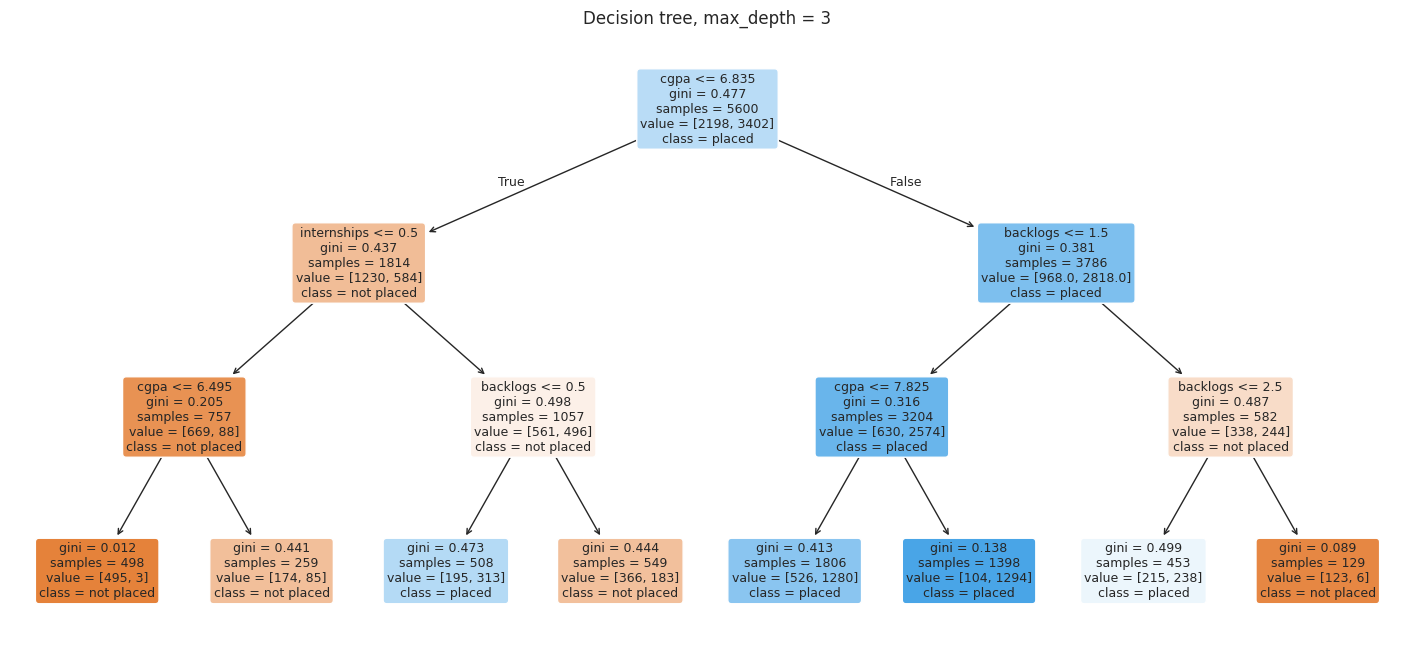

In [15]:
small_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(small_tree, feature_names=feature_cols, class_names=['not placed', 'placed'],
          filled=True, rounded=True, fontsize=9)
plt.title('Decision tree, max_depth = 3')
plt.show()

In [16]:
print(export_text(small_tree, feature_names=feature_cols))

|--- cgpa <= 6.84
|   |--- internships <= 0.50
|   |   |--- cgpa <= 6.49
|   |   |   |--- class: 0
|   |   |--- cgpa >  6.49
|   |   |   |--- class: 0
|   |--- internships >  0.50
|   |   |--- backlogs <= 0.50
|   |   |   |--- class: 1
|   |   |--- backlogs >  0.50
|   |   |   |--- class: 0
|--- cgpa >  6.84
|   |--- backlogs <= 1.50
|   |   |--- cgpa <= 7.83
|   |   |   |--- class: 1
|   |   |--- cgpa >  7.83
|   |   |   |--- class: 1
|   |--- backlogs >  1.50
|   |   |--- backlogs <= 2.50
|   |   |   |--- class: 1
|   |   |--- backlogs >  2.50
|   |   |   |--- class: 0



**Reading each box:** the first line is the question; `gini` is that node's impurity (lower = purer); `samples` is how many training students reached it; `value` is [not placed, placed]; `class` is the majority answer; the colour shows which class dominates (deeper colour = purer).

## Practice - change max_depth, watch overfitting

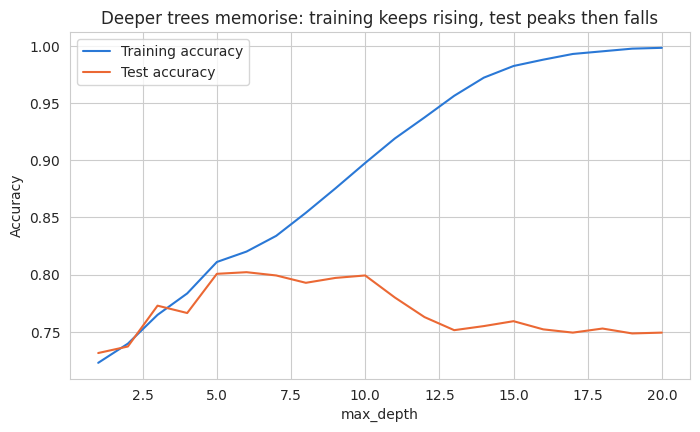

Best max_depth by test accuracy: 6 -> 0.802


In [17]:
depths = list(range(1, 21))
train_accs, test_accs = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_accs.append(tree.score(X_train, y_train))
    test_accs.append(tree.score(X_test, y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_accs, label='Training accuracy', color='#2a78d6')
plt.plot(depths, test_accs, label='Test accuracy', color='#eb6834')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Deeper trees memorise: training keeps rising, test peaks then falls')
plt.legend()
plt.show()

best_depth = depths[int(np.argmax(test_accs))]
print('Best max_depth by test accuracy:', best_depth, '->', round(max(test_accs), 3))

## Hyperparameters side by side, and pruning

In [18]:
configs = {
    'no limits':                           dict(),
    'max_depth=4':                         dict(max_depth=4),
    'max_depth=6':                         dict(max_depth=6),
    'max_depth=8, min_samples_leaf=30':    dict(max_depth=8, min_samples_leaf=30),
    'max_depth=8, min_samples_split=80':   dict(max_depth=8, min_samples_split=80),
    'entropy, max_depth=6':                dict(criterion='entropy', max_depth=6),
}
rows = []
for name, params in configs.items():
    t = DecisionTreeClassifier(random_state=42, **params).fit(X_train, y_train)
    rows.append({'config': name, 'leaves': t.get_n_leaves(),
                 'train_acc': round(t.score(X_train, y_train), 3),
                 'test_acc': round(t.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,config,leaves,train_acc,test_acc
0,no limits,869,1.000,0.757
1,max_depth=4,16,0.784,0.766
2,max_depth=6,58,0.820,0.802
3,"max_depth=8, min_samples_leaf=30",90,0.835,0.813
4,"max_depth=8, min_samples_split=80",81,0.833,0.811
5,"entropy, max_depth=6",57,0.809,0.803


In [19]:
# Post-pruning: a bigger ccp_alpha cuts away more branches
rows = []
for a in [0, 0.0005, 0.001, 0.003, 0.01]:
    t = DecisionTreeClassifier(random_state=42, ccp_alpha=a).fit(X_train, y_train)
    rows.append({'ccp_alpha': a, 'leaves': t.get_n_leaves(),
                 'train_acc': round(t.score(X_train, y_train), 3),
                 'test_acc': round(t.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,ccp_alpha,leaves,train_acc,test_acc
0,0.0000,869,1.000,0.757
1,0.0005,102,0.861,0.796
2,0.0010,40,0.824,0.807
3,0.0030,16,0.802,0.801
4,0.0100,6,0.740,0.737


## Which features does ONE tree rely on?

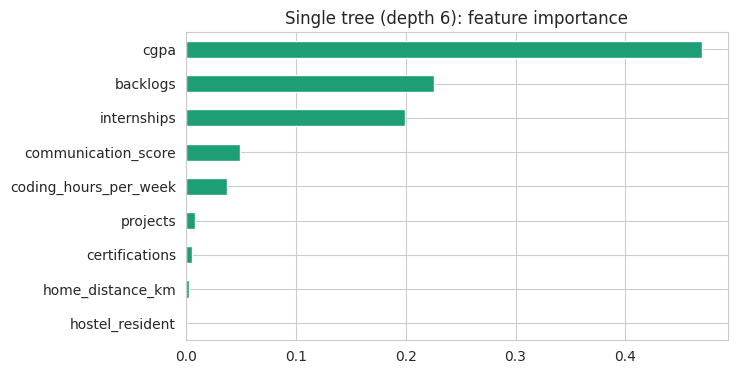

In [20]:
tree6 = DecisionTreeClassifier(max_depth=6, random_state=42).fit(X_train, y_train)
tree_imp = pd.Series(tree6.feature_importances_, index=feature_cols).sort_values()

tree_imp.plot(kind='barh', color='#1D9E75', figsize=(7, 4))
plt.title('Single tree (depth 6): feature importance')
plt.show()

## 2.5 Decision tree as a REGRESSOR
Built the same way, with two differences: splits are chosen to reduce the **spread (squared error)** of the target inside each group, and each leaf predicts the **average** of its students. The prediction is a staircase.

**Analogy:** estimating a placed student's package by asking "what CGPA band? any internship?" and quoting the average package of past students who landed in the same final group.

We predict `package_lpa` using ONLY the placed students (the others have no package).

In [21]:
placed_df = df[df['placed'] == 1].copy()          # keep only placed students - they are the only ones with a package
Xr = placed_df[feature_cols].values
yr = placed_df['package_lpa'].values
print('Placed students:', len(placed_df), '| missing packages left:', int(np.isnan(yr).sum()))

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

rows = []
for d in [2, 4, 6, 10, None]:
    reg = DecisionTreeRegressor(max_depth=d, random_state=42).fit(Xr_train, yr_train)
    rows.append({'max_depth': d,
                 'train_R2': round(reg.score(Xr_train, yr_train), 3),
                 'test_R2': round(reg.score(Xr_test, yr_test), 3),
                 'test_MAE_lpa': round(mean_absolute_error(yr_test, reg.predict(Xr_test)), 2)})
pd.DataFrame(rows)

Placed students: 4252 | missing packages left: 0


,max_depth,train_R2,test_R2,test_MAE_lpa
0,2.0,0.431,0.442,1.02
1,4.0,0.558,0.517,0.95
2,6.0,0.655,0.542,0.92
3,10.0,0.843,0.517,0.94
4,NaN,1.000,0.341,1.13


In [22]:
tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42).fit(Xr_train, yr_train)
pred_tree_reg = tree_reg.predict(Xr_test)
print(f'Tree regressor (depth 5)  MAE: {mean_absolute_error(yr_test, pred_tree_reg):.2f} LPA | '
      f'RMSE: {np.sqrt(mean_squared_error(yr_test, pred_tree_reg)):.2f} LPA | R2: {r2_score(yr_test, pred_tree_reg):.3f}')

Tree regressor (depth 5)  MAE: 0.93 LPA | RMSE: 1.17 LPA | R2: 0.536


---
# Part 3 - Ensembles and Bagging

## 3.1 The problem with ONE tree: it is unstable
A single deep tree fits its training data tightly. Change the training data a little and you can get a noticeably different tree and different predictions. That sensitivity is called **high variance**. It is the reason a lone tree overfits.

**Analogy - one nervous expert:** a single recruiter who made a snap judgement based on whichever 50 CVs they happened to read that morning. Another recruiter, who read a slightly different 50 CVs, might decide quite differently.

## 3.2 The wisdom of crowds - ensemble learning
**Ensemble learning** = combine the predictions of many models instead of trusting one.

**Analogy 1 - the jellybean jar:** ask 100 people to guess how many jellybeans are in a jar. Individual guesses are wild, but the AVERAGE of the crowd is usually remarkably close - the random over- and under-estimates cancel out.
**Analogy 2 - an interview panel:** a panel of 100 interviewers voting beats a single interviewer, because one person's mood or bias gets outvoted.

## 3.3 Bagging = Bootstrap AGGregatING
1. **Bootstrap:** from N training students, draw N students **at random WITH replacement** to form a new training set. Some students appear several times; others do not appear at all.
2. Train one tree on each bootstrap sample (e.g. 100 samples -> 100 trees).
3. **Aggregate:** classification = **majority vote** of the trees; regression = **average** of the trees' predictions.

```
                 Training data (N students)
                          |
        random draws WITH replacement (bootstrap)
      +-------------------+--------------------+
      v                   v                    v
  Sample 1            Sample 2     ...     Sample B
      |                   |                    |
   Tree 1              Tree 2      ...      Tree B
      |                   |                    |
 prediction 1        prediction 2  ...   prediction B
      +-------------------+--------------------+
                          v
        classification: majority VOTE  |  regression: AVERAGE
                          v
                  final prediction
```

**Analogy - photocopied notes:** each student in a study group gets a photocopy of the class notes in which some pages are repeated and others missing (a random draw WITH replacement). Each studies on their own copy, and the group answers by vote. No single student's missing pages ruin the answer.

**How much of the data does one bootstrap sample contain?** Each student has probability (1 - 1/N)^N of being left out of a sample, which approaches 1/e, about **36.8%**. So a bootstrap sample holds about **63.2% of the distinct students**; the rest (about 36.8%) are **out-of-bag (OOB)** for that tree - we will use them as a free validation set later.

## Implementation 1 - what a bootstrap sample looks like

In [23]:
rng = np.random.default_rng(0)
n_train = len(X_train)

sample_idx = rng.choice(n_train, size=n_train, replace=True)     # draw N students WITH replacement
unique_share = len(np.unique(sample_idx)) / n_train
print(f'Distinct students in one bootstrap sample: {unique_share:.1%}   (theory says about 63.2%)')
print(f'Students left OUT of this sample (out-of-bag): {1 - unique_share:.1%}   (theory: about 36.8%)')

Distinct students in one bootstrap sample: 63.8%   (theory says about 63.2%)
Students left OUT of this sample (out-of-bag): 36.2%   (theory: about 36.8%)


## Implementation 2 - bagging from scratch with 25 trees
We build 25 full trees, each on its own bootstrap sample, then take a majority vote. We also measure how much the trees **disagree** with each other - the more they disagree, the more the vote has to work with.

In [24]:
rng = np.random.default_rng(0)
n_trees = 25
all_preds, tree_accs = [], []

for t in range(n_trees):
    # FIX ME: a bootstrap sample must be drawn WITH replacement, but this line draws WITHOUT replacement,
    # so every "sample" is just the whole training set shuffled and all 25 trees learn the same thing.
    # Hint: look at the "distinct students" figure printed below - it should be about 63%, not 100%.
    idx = rng.choice(n_train, size=n_train, replace=False)

    if t == 0:
        print(f'Distinct students in tree 1 sample: {len(np.unique(idx)) / n_train:.1%}')

    tree = DecisionTreeClassifier(random_state=t).fit(X_train[idx], y_train[idx])
    pred = tree.predict(X_test)
    all_preds.append(pred)
    tree_accs.append((pred == y_test).mean())

all_preds = np.array(all_preds)                                  # shape: (25 trees, test students)
vote = (all_preds.mean(axis=0) >= 0.5).astype(int)               # majority vote across the 25 trees
disagree = ((all_preds.min(axis=0) != all_preds.max(axis=0))).mean()

print(f'Average accuracy of ONE tree:        {np.mean(tree_accs):.3f}')
print(f'Accuracy of the 25-tree vote:        {(vote == y_test).mean():.3f}')
print(f'Test students the trees disagree on: {disagree:.1%}')

Distinct students in tree 1 sample: 100.0%
Average accuracy of ONE tree:        0.749
Accuracy of the 25-tree vote:        0.749
Test students the trees disagree on: 12.5%


**What to expect once fixed:** individual bootstrap trees are only about as good as a single full tree, but they make DIFFERENT mistakes, so on many students they disagree - and the majority vote beats the average individual tree clearly. If your vote accuracy is no better than a single tree's and the trees agree on most students, your bootstrap is not really random yet.

---
# Part 4 - Random Forest

## 4.1 Bagging plus ONE more trick: random features at each split
Bagging alone has a weakness. If one feature (say `cgpa`) is much stronger than the rest, EVERY bagged tree will pick it for its first split, and the trees end up looking alike. **Trees that make the same mistakes cannot cancel each other's errors** - averaging similar opinions gains little.

A **random forest** fixes this: at **every split**, each tree may only consider a **random subset of the features** (`max_features`). Sometimes `cgpa` is not even allowed in the room, so other features get a chance and the trees become genuinely different.

**Analogy - a diverse interview panel:** if every interviewer judges on CGPA first, the panel is really one opinion repeated 100 times. If each interviewer, at each stage, can only look at a few randomly chosen criteria, the panel brings different viewpoints - and their combined vote is far more reliable.

> **Random forest = many decision trees (each on a bootstrap sample) + random feature subsets at every split + vote/average.**

## 4.2 Bias-variance, revisited - why a forest beats one tree
- **Bias** = error from being too simple (underfitting). **Variance** = error from being too sensitive to the particular training data (overfitting).

| Model | Bias | Variance | Comment |
|---|---|---|---|
| Shallow tree | higher | lower | too simple, underfits |
| Deep (full) tree | low | **high** | memorises, unstable |
| Random forest | low | **much lower** | many different deep trees, errors average out |

A forest keeps the low bias of deep trees but slashes the variance by averaging. In maths: for B trees whose predictions each have variance s^2 and pairwise correlation r,

```
Variance of the average  =  r x s^2  +  (1 - r) x s^2 / B
```
- More trees (bigger B) kills the second term.
- Random feature subsets make the trees less alike (smaller r), which shrinks the first term.

That is exactly why we need BOTH tricks: bootstrap + random features.

**Why a forest beats one tree, in one line:** a single tree is a nervous expert who overfits; a forest is a calm committee of different experts whose individual mistakes cancel out.

## 4.3 Hyperparameters

| Hyperparameter | What it controls | Typical effect |
|---|---|---|
| `n_estimators` | number of trees | more trees = more stable, then it plateaus (just slower) |
| `max_features` | features each split may consider (`'sqrt'` is the default for classification) | smaller = more diverse trees (lower correlation) but each tree is weaker |
| `max_depth` | depth of each tree | limits memorising; `None` = grow fully |
| `min_samples_leaf` | minimum students per leaf | larger = smoother trees |
| `oob_score` | score the forest on out-of-bag rows | a free validation estimate |
| `random_state` | seed for repeatable results | - |

## Implementation 1 - single tree vs bagging vs random forest

In [25]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')        # few-tree OOB warnings are harmless here

    bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=200,
                            oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rf = RandomForestClassifier(n_estimators=200, oob_score=True,
                                random_state=42, n_jobs=-1).fit(X_train, y_train)

models = {
    'Single tree (no limits)':        full_tree,
    'Single tree (max_depth=6)':      tree6,
    'Bagging (200 full trees)':       bag,
    'Random forest (200 trees)':      rf,
}

rows = []
for name, m in models.items():
    r = evaluate(name, y_test, m.predict(X_test), m.predict_proba(X_test)[:, 1])
    r['train_acc'] = m.score(X_train, y_train)
    rows.append(r)

results = pd.DataFrame(rows).set_index('model')
results['train_test_gap'] = results['train_acc'] - results['accuracy']
results[['train_acc', 'accuracy', 'train_test_gap', 'precision', 'recall', 'specificity', 'f1', 'auc']].round(3)

,train_acc,accuracy,train_test_gap,precision,recall,specificity,f1,auc
model,,,,,,,,
Single tree (no limits),1.00,0.757,0.243,0.812,0.781,0.720,0.796,0.751
Single tree (max_depth=6),0.82,0.802,0.018,0.806,0.888,0.669,0.845,0.879
Bagging (200 full trees),1.00,0.816,0.184,0.834,0.871,0.733,0.852,0.904
Random forest (200 trees),1.00,0.826,0.174,0.837,0.885,0.735,0.860,0.907


Read the table: the single full tree has a big train-test gap (memorising). Bagging and the forest keep a perfect-looking training score too, but their **test** scores are clearly higher - the averaging cancelled the memorised noise.

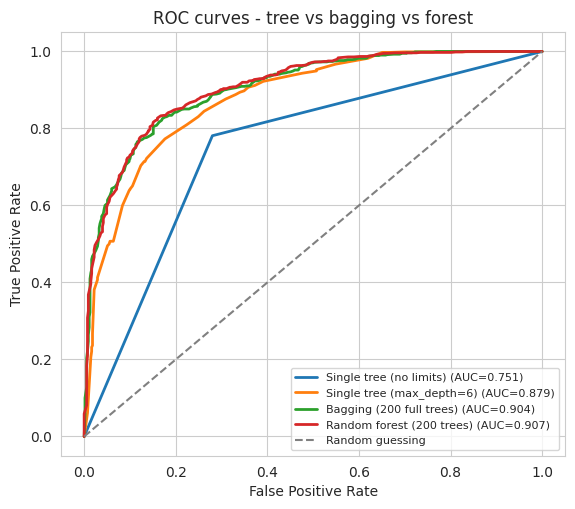

In [26]:
plt.figure(figsize=(6.5, 5.5))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves - tree vs bagging vs forest')
plt.legend(fontsize=8)
plt.show()

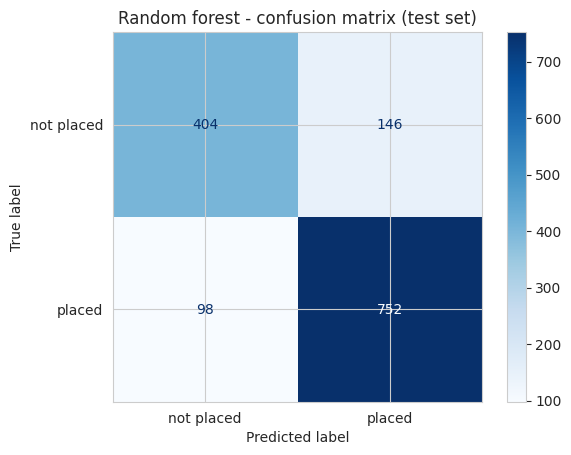

In [27]:
show_confusion(y_test, rf.predict(X_test), 'Random forest - confusion matrix (test set)')

## Implementation 2 - more trees: how many are enough?
We grow forests of increasing size. **Test accuracy** should rise and then flatten - extra trees beyond that point only cost time.

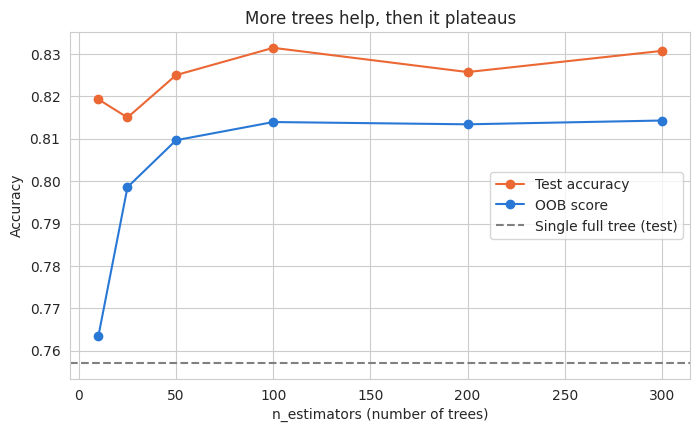

,n_estimators,test_acc,oob_score
0,10,0.819,0.763
1,25,0.815,0.799
2,50,0.825,0.810
3,100,0.831,0.814
4,200,0.826,0.813
5,300,0.831,0.814


In [28]:
sizes = [10, 25, 50, 100, 200, 300]
test_scores, oob_scores = [], []

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for n in sizes:
        m = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
        test_scores.append(m.score(X_test, y_test))
        oob_scores.append(m.oob_score_)

plt.figure(figsize=(8, 4.5))
plt.plot(sizes, test_scores, marker='o', label='Test accuracy', color='#eb6834')
plt.plot(sizes, oob_scores, marker='o', label='OOB score', color='#2a78d6')
plt.axhline(full_tree.score(X_test, y_test), color='gray', linestyle='--', label='Single full tree (test)')
plt.xlabel('n_estimators (number of trees)')
plt.ylabel('Accuracy')
plt.title('More trees help, then it plateaus')
plt.legend()
plt.show()

pd.DataFrame({'n_estimators': sizes, 'test_acc': np.round(test_scores, 3), 'oob_score': np.round(oob_scores, 3)})

## 4.4 Out-of-bag (OOB) score - a free validation set
Each tree was trained on a bootstrap sample that left out about 36.8% of the students. For any student, we can ask only the trees that **never saw them** to vote - and compare with the truth. Average over all students and you get the **OOB score**: an honest accuracy estimate, with no separate validation set needed.

**Analogy:** in the photocopied-notes study group, each student missed some pages. Test each student ONLY on the pages missing from their own copy - that is a fair exam of what they truly understand.

OOB is especially handy when data is scarce, because you do not have to sacrifice rows for validation.

In [29]:
print(f'OOB score (no test data used):  {rf.oob_score_:.3f}')
print(f'Actual test accuracy:             {rf.score(X_test, y_test):.3f}')
print(f'Bagging OOB score:                {bag.oob_score_:.3f}')
print('\nThe OOB score should land close to the test accuracy - it is a free preview of how the model will do on unseen data.')

OOB score (no test data used):  0.813
Actual test accuracy:             0.826
Bagging OOB score:                0.815

The OOB score should land close to the test accuracy - it is a free preview of how the model will do on unseen data.


## 4.5 max_features - how many features may each split see?
The default for classification is `sqrt(number of features)`; with 9 features that is 3. Too small and each tree is weak; the maximum (all 9) makes the trees alike again (which is just bagging). Let's see.

In [30]:
rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for mf in [1, 2, 3, 5, 9]:
        m = RandomForestClassifier(n_estimators=200, max_features=mf, oob_score=True,
                                   random_state=42, n_jobs=-1).fit(X_train, y_train)
        rows.append({'max_features': mf, 'test_acc': round(m.score(X_test, y_test), 3),
                     'oob_score': round(m.oob_score_, 3)})
pd.DataFrame(rows)

,max_features,test_acc,oob_score
0,1,0.823,0.811
1,2,0.833,0.821
2,3,0.826,0.813
3,5,0.826,0.814
4,9,0.816,0.814


The differences above are small - a few tenths of a percent can simply be noise from the random train/test split. Do not over-read them. The practical lesson: using only 1 feature per split or ALL features per split rarely wins, and the default (`sqrt`) is a sound starting point.

## 4.6 Feature importance - which columns does the forest rely on?

**Mean decrease in impurity (MDI)** - sklearn's built-in `feature_importances_`: each time a feature is used for a split, note how much the impurity dropped; add it up over every tree and normalise. Larger = that feature did more of the sorting.

**Caution:** MDI is computed on the TRAINING data and tends to favour features with many distinct values (like `home_distance_km`), even useless ones. So we cross-check with:

**Permutation importance** - take the TEST set, **shuffle one column** (destroying its information), and measure how much the score drops. A big drop = the model truly needed that feature. **Analogy:** remove one player from a team and see how badly the score falls; if nothing changes, that player was not contributing.

## Practice - plot the feature importances

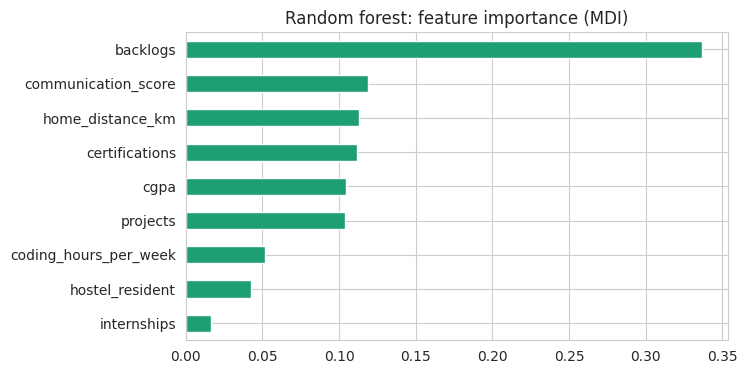

In [31]:
# FIX ME: the values in rf.feature_importances_ follow the ORIGINAL column order (feature_cols), but the
# labels below are put in ALPHABETICAL order, so every bar gets the wrong name.
# Hint: after fixing, cgpa should be the clear winner in BOTH this plot and the permutation-importance
# table in the next cell. If the two disagree about the top feature, the labels are wrong.
rf_imp = pd.Series(rf.feature_importances_, index=sorted(feature_cols)).sort_values()

rf_imp.plot(kind='barh', color='#1D9E75', figsize=(7, 4))
plt.title('Random forest: feature importance (MDI)')
plt.show()

In [32]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=feature_cols)

compare = pd.DataFrame({'MDI importance': rf_imp, 'Permutation importance': perm_imp}).sort_values('Permutation importance')
compare.round(4)

,MDI importance,Permutation importance
home_distance_km,0.1129,-0.0015
hostel_resident,0.0427,-0.0014
projects,0.1042,0.0005
certifications,0.1118,0.0091
coding_hours_per_week,0.0519,0.0154
communication_score,0.1191,0.0156
internships,0.0162,0.0697
backlogs,0.3370,0.0708
cgpa,0.1042,0.1751


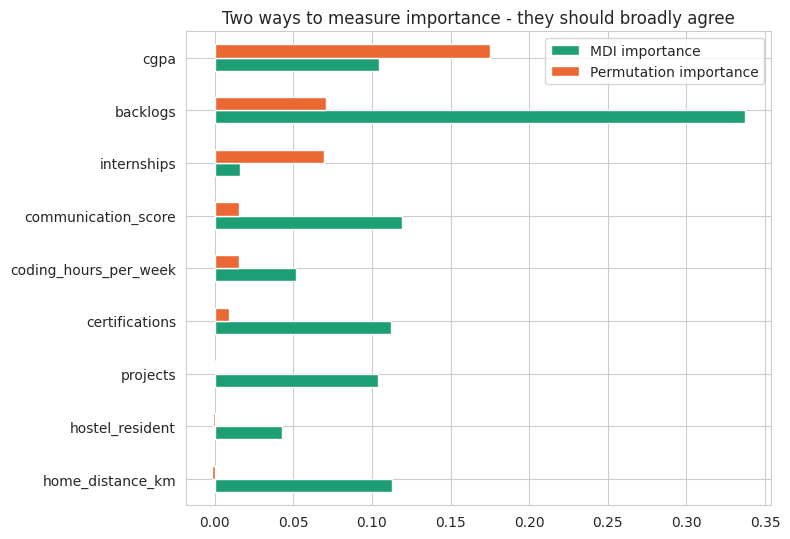

In [33]:
compare.plot(kind='barh', figsize=(8, 5.5), color=['#1D9E75', '#eb6834'])
plt.title('Two ways to measure importance - they should broadly agree')
plt.tight_layout()
plt.show()

**What to notice (once your labels are fixed):**
- `cgpa` comes out on top in both methods, and `backlogs`, `internships` and `coding_hours_per_week` also matter under permutation importance.
- **`home_distance_km` is a useless column, yet the built-in (MDI) importance gives it a sizeable score** - comparable to genuinely useful features - while its permutation importance is about zero or even slightly negative. MDI is measured on training data and favours columns with many distinct values, so a random-looking number column can look important. Permutation importance, measured on unseen test data, is not fooled.
- `hostel_resident` has only two possible values, so MDI barely uses it - it looks harmless on both.

**Take-away:** trust permutation importance (or at least cross-check) before telling anyone which features "matter".

## 4.7 Random forest as a REGRESSOR
Same forest idea, but each tree predicts a number and the forest **averages** them. We compare with the single regression tree from Part 2 on the placed students.

In [34]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    rf_reg = RandomForestRegressor(n_estimators=200, oob_score=True, random_state=42, n_jobs=-1).fit(Xr_train, yr_train)

full_reg = DecisionTreeRegressor(random_state=42).fit(Xr_train, yr_train)

rows = []
for name, m in [('Single tree (no limits)', full_reg), ('Single tree (max_depth=5)', tree_reg), ('Random forest (200 trees)', rf_reg)]:
    p = m.predict(Xr_test)
    rows.append({'model': name, 'train_R2': round(m.score(Xr_train, yr_train), 3),
                 'test_R2': round(r2_score(yr_test, p), 3),
                 'MAE_lpa': round(mean_absolute_error(yr_test, p), 2),
                 'RMSE_lpa': round(float(np.sqrt(mean_squared_error(yr_test, p))), 2)})
print('Forest OOB R2:', round(rf_reg.oob_score_, 3))
pd.DataFrame(rows).set_index('model')

Forest OOB R2: 0.662


,train_R2,test_R2,MAE_lpa,RMSE_lpa
model,,,,
Single tree (no limits),1.000,0.341,1.13,1.39
Single tree (max_depth=5),0.608,0.536,0.93,1.17
Random forest (200 trees),0.954,0.651,0.81,1.01


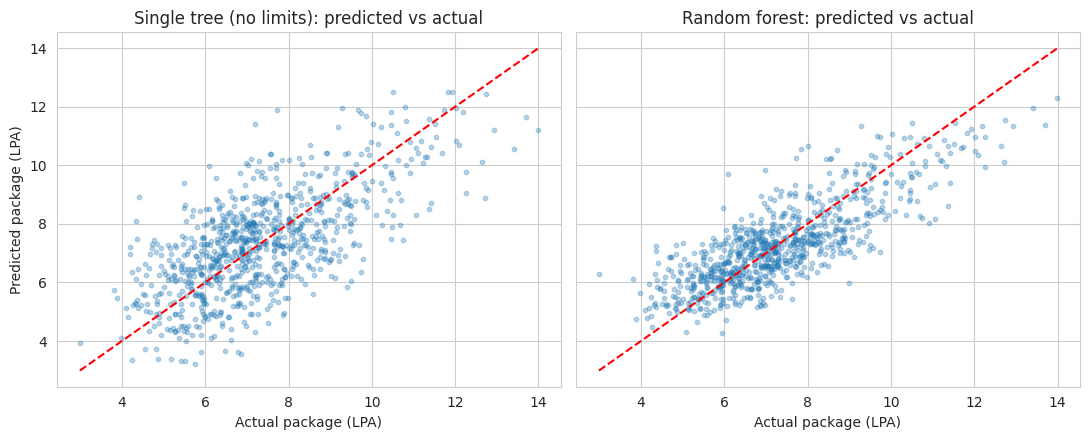

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, [('Single tree (no limits)', full_reg), ('Random forest', rf_reg)]):
    p = m.predict(Xr_test)
    ax.scatter(yr_test, p, alpha=0.3, s=10)
    lims = [yr_test.min(), yr_test.max()]
    ax.plot(lims, lims, color='red', linestyle='--')
    ax.set_title(f'{name}: predicted vs actual')
    ax.set_xlabel('Actual package (LPA)')
axes[0].set_ylabel('Predicted package (LPA)')
plt.tight_layout()
plt.show()

---
## Why a forest beats one tree - the summary
1. A single deep tree has **low bias but high variance**: it memorises its training data and changes a lot if the data changes.
2. **Bagging** trains many trees on different bootstrap samples and averages them, which cancels much of that variance.
3. **Random feature subsets** make the trees less alike, so their errors cancel better.
4. The result keeps the low bias of deep trees with far lower variance - better test accuracy, and the OOB score gives a free honest estimate.

*The price:* a forest is harder to interpret than one tree (you cannot draw 200 trees on a whiteboard) and slower to train and predict. Feature importance is how we recover some interpretability.

## Recap
- **Decision tree:** flowchart of yes/no questions; splits chosen by Gini or entropy (information gain); leaves hold the answer (majority class or average value); control overfitting with pruning - `max_depth`, `min_samples_split`, `min_samples_leaf`, `ccp_alpha`.
- **Entropy vs Gini:** both measure impurity, nearly identical in practice; Gini is the faster default.
- **Ensemble:** combine many models. **Bagging:** bootstrap samples (with replacement) + vote/average.
- **Random forest:** bagging + random features at each split; `n_estimators`, `max_features`, `max_depth`.
- **OOB score:** each tree is tested on the ~36.8% of rows it never saw - a free validation estimate.
- **Feature importance:** MDI (built in, can be biased) and permutation importance (shuffle a column on test data).
- **Bias-variance:** a forest keeps low bias and cuts variance; Variance of the average = r x s^2 + (1 - r) x s^2 / B.

---

## Assignment
1. Fix both `# FIX ME` bugs and re-run the notebook from the top. Report the corrected vote accuracy of your hand-made bagging ensemble vs the average single tree.
2. **Change max_depth:** report the depth where a single tree's test accuracy peaks, and the depth after which it overfits.
3. **Plot feature importances** for the forest (MDI and permutation) and name the top 3 features. Do the irrelevant columns rank low? Why can MDI still give them a small non-zero value?
4. Vary `n_estimators` (try 5, 20, 100, 500) and `max_features`; describe what changes and where more trees stop helping.
5. In your own words (markdown cell): **why does a random forest beat a single decision tree?** Mention bias, variance, bootstrap and random features.
6. Compare `criterion='gini'` vs `'entropy'` for a forest on this data - does it matter?
